***Oasis Infobyte — Data Analytics Internship***

***Level 2 | Task 5: Autocomplete and Autocorrect Data Analytics***

***Dataset: WikiText-2 (Wikipedia-derived English Text Corpus)***

***STEP 1 — Install required libraries***

In [1]:
!pip -q install nltk scikit-learn seaborn

***STEP 2 — Import libraries***

In [2]:
import re
import json
import gzip
import pickle
import random
import math
import os

from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords

from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix
)

from IPython.display import display

random.seed(42)
np.random.seed(42)

nltk.download("stopwords", quiet=True)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


***STEP 3 — Upload WikiText datasets***

In [3]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving wikitext_train.csv to wikitext_train.csv
Saving wikitext_test.csv to wikitext_test.csv
Saving wikitext_validation.csv to wikitext_validation.csv
Uploaded files:
wikitext_train.csv
wikitext_test.csv
wikitext_validation.csv


***STEP 4 — Load all datasets***

In [4]:
train_df = pd.read_csv("wikitext_train.csv")
val_df = pd.read_csv("wikitext_validation.csv")
test_df = pd.read_csv("wikitext_test.csv")

print("Training dataset:", train_df.shape)
print("Validation dataset:", val_df.shape)
print("Testing dataset:", test_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nFirst 10 training rows:")
display(train_df.head(10))

Training dataset: (36718, 1)
Validation dataset: (3760, 1)
Testing dataset: (4358, 1)

Column names:
['text']

First 10 training rows:


,text
0,NaN
1,= Valkyria Chronicles III = \n
2,NaN
3,Senjō no Valkyria 3 : Unrecorded Chronicles (...
4,"The game began development in 2010 , carrying..."
5,"It met with positive sales in Japan , and was..."
6,NaN
7,= = Gameplay = = \n
8,NaN
9,"As with previous Valkyira Chronicles games , ..."


***STEP 5 — Initial data inspection***

In [5]:
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n===== {name} Dataset =====")

    print("Rows:", len(df))
    print("Columns:", df.shape[1])
    print("Missing text:", df["text"].isna().sum())
    print("Duplicate text:", df["text"].duplicated().sum())

    print("\nData types:")
    print(df.dtypes)


===== Training Dataset =====
Rows: 36718
Columns: 1
Missing text: 12951
Duplicate text: 15004

Data types:
text    object
dtype: object

===== Validation Dataset =====
Rows: 3760
Columns: 1
Missing text: 1299
Duplicate text: 1398

Data types:
text    object
dtype: object

===== Testing Dataset =====
Rows: 4358
Columns: 1
Missing text: 1467
Duplicate text: 1565

Data types:
text    object
dtype: object


**PART 2 — Text preprocessing**

***STEP 6 — Remove missing and empty text***

In [6]:
def clean_lines(frame):
    texts = frame["text"].dropna().astype(str).str.strip()

    texts = texts[texts.str.len() > 0]

    # Clean common WikiText formatting artifacts
    texts = texts.str.replace("@-@", "-", regex=False)
    texts = texts.str.replace("@,@", ",", regex=False)
    texts = texts.str.replace("<unk>", " ", regex=False)

    return texts.tolist()


train_lines = clean_lines(train_df)
val_lines = clean_lines(val_df)
test_lines = clean_lines(test_df)

print("Cleaned training lines:", len(train_lines))
print("Cleaned validation lines:", len(val_lines))
print("Cleaned testing lines:", len(test_lines))

print("\nExample cleaned text:")
print(train_lines[1][:300])

Cleaned training lines: 23767
Cleaned validation lines: 2461
Cleaned testing lines: 2891

Example cleaned text:
Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role - playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January


***STEP 7 — Lowercasing, punctuation removal ও tokenization***

In [7]:
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")

def tokenize(text):
    return WORD_RE.findall(str(text).lower())


train_sentences = [
    tokens
    for line in train_lines
    if (tokens := tokenize(line))
]

val_sentences = [
    tokens
    for line in val_lines
    if (tokens := tokenize(line))
]

test_sentences = [
    tokens
    for line in test_lines
    if (tokens := tokenize(line))
]

print("Training sequences:", len(train_sentences))
print("Validation sequences:", len(val_sentences))
print("Testing sequences:", len(test_sentences))

print("\nTokenized example:")
print(train_sentences[1][:30])

Training sequences: 23692
Validation sequences: 2454
Testing sequences: 2889

Tokenized example:
['senj', 'no', 'valkyria', 'unrecorded', 'chronicles', 'japanese', 'lit', 'valkyria', 'of', 'the', 'battlefield', 'commonly', 'referred', 'to', 'as', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', 'is', 'a', 'tactical', 'role', 'playing', 'video', 'game', 'developed', 'by', 'sega']


***STEP 8 — Stopword removal***

In [8]:
stop_set = set(stopwords.words("english"))

train_tokens = [
    word
    for sentence in train_sentences
    for word in sentence
]

train_tokens_no_stop = [
    word
    for word in train_tokens
    if word not in stop_set and len(word) > 1
]

print("Total training tokens:", len(train_tokens))
print("Tokens after stopword removal:", len(train_tokens_no_stop))

print("\nExample:")
print(train_tokens_no_stop[:30])

Total training tokens: 1694385
Tokens after stopword removal: 972645

Example:
['valkyria', 'chronicles', 'iii', 'senj', 'valkyria', 'unrecorded', 'chronicles', 'japanese', 'lit', 'valkyria', 'battlefield', 'commonly', 'referred', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', 'tactical', 'role', 'playing', 'video', 'game', 'developed', 'sega', 'media', 'vision', 'playstation', 'portable', 'released']


***STEP 9 — Dataset statistics***

In [9]:
summary = pd.DataFrame([
    {
        "Split": name,
        "Nonempty_Lines": len(lines),
        "Tokens": sum(map(len, sentences)),
        "Unique_Words": len(set(
            word
            for sentence in sentences
            for word in sentence
        ))
    }
    for name, lines, sentences in [
        ("Train", train_lines, train_sentences),
        ("Validation", val_lines, val_sentences),
        ("Test", test_lines, test_sentences)
    ]
])

display(summary)

,Split,Nonempty_Lines,Tokens,Unique_Words
0,Train,23767,1694385,61887
1,Validation,2461,177008,16473
2,Test,2891,198980,17685


***STEP 10 — Top 20 most frequent words***

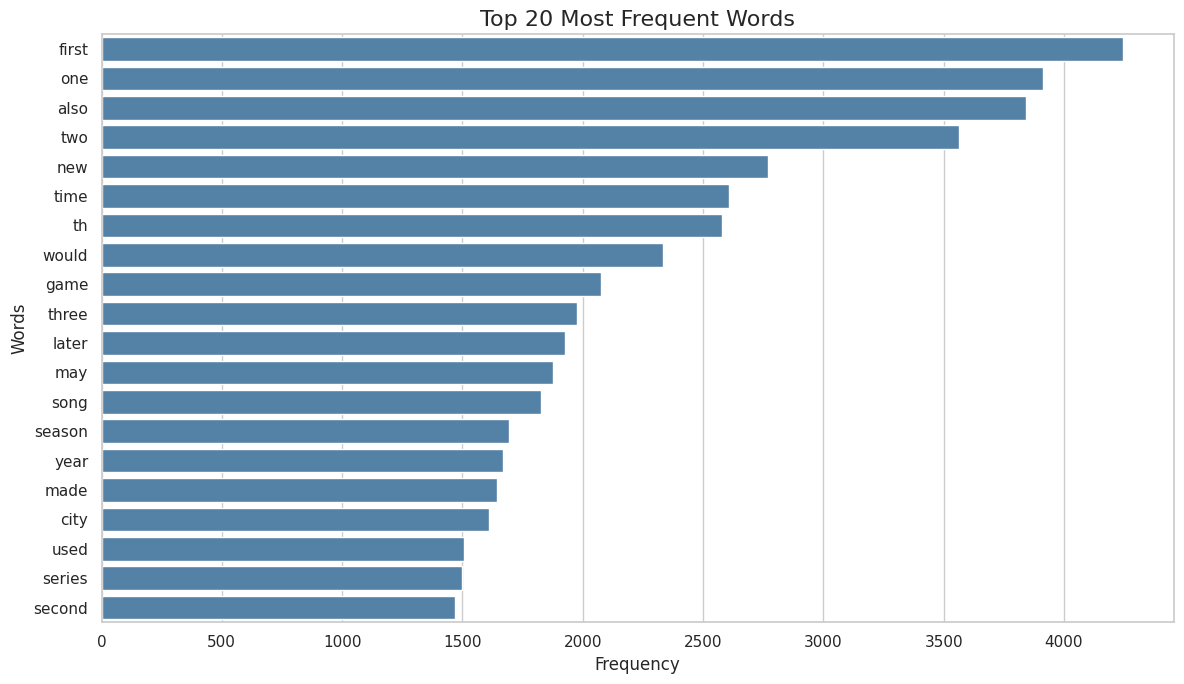

,Word,Frequency
0,first,4245
1,one,3914
2,also,3842
3,two,3565
4,new,2768
5,time,2607
6,th,2579
7,would,2332
8,game,2077
9,three,1976


In [10]:
word_counts = Counter(train_tokens_no_stop)

top20 = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top20,
    x="Frequency",
    y="Word",
    color="steelblue"
)

plt.title("Top 20 Most Frequent Words", fontsize=16)
plt.xlabel("Frequency")
plt.ylabel("Words")

plt.tight_layout()
plt.savefig("top20_words.png", dpi=170)
plt.show()

display(top20)

***STEP 11 — Word length ও text length visualization***

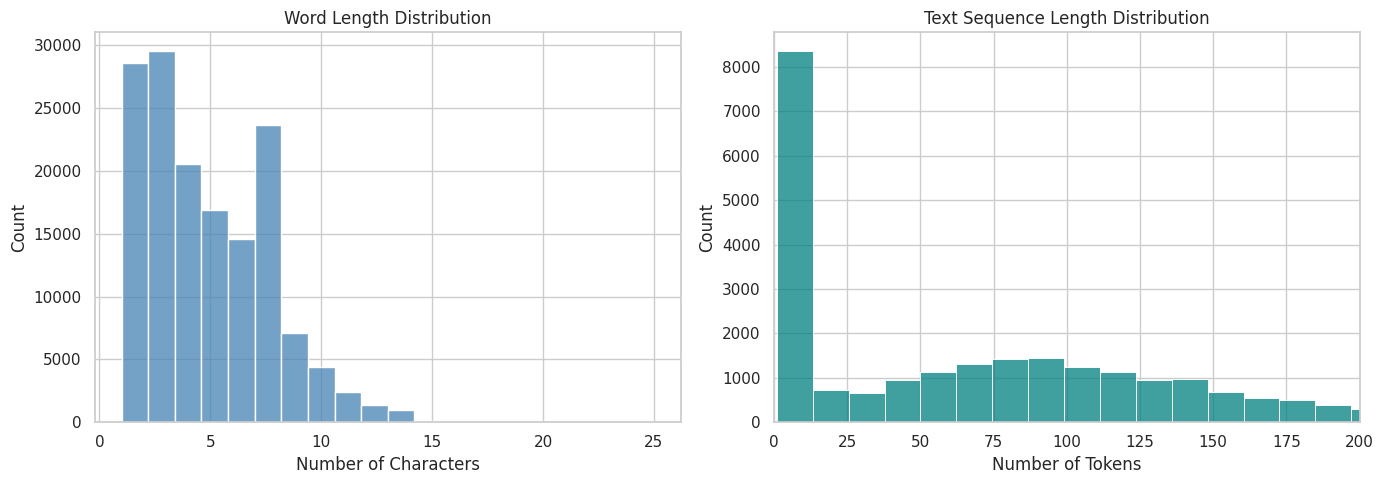

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

word_lengths = [
    len(word) for word in train_tokens[:150000]
]

sentence_lengths = [
    len(sentence) for sentence in train_sentences
]

sns.histplot(
    word_lengths,
    bins=20,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Word Length Distribution")
axes[0].set_xlabel("Number of Characters")

sns.histplot(
    sentence_lengths,
    bins=50,
    ax=axes[1],
    color="teal"
)

axes[1].set_xlim(0, 200)
axes[1].set_title("Text Sequence Length Distribution")
axes[1].set_xlabel("Number of Tokens")

plt.tight_layout()
plt.savefig("text_distributions.png", dpi=170)
plt.show()

**PART 3 — Making Autocomplete model**

***STEP 12 — Build Bigram and Trigram models***

In [12]:
unigrams = Counter()
bigrams = defaultdict(Counter)
trigrams = defaultdict(Counter)

for words in train_sentences:

    unigrams.update(words)

    for i in range(1, len(words)):
        previous_word = words[i - 1]
        current_word = words[i]

        bigrams[previous_word][current_word] += 1

    for i in range(2, len(words)):
        context = (words[i - 2], words[i - 1])
        current_word = words[i]

        trigrams[context][current_word] += 1

print("Vocabulary size:", len(unigrams))
print("Bigram contexts:", len(bigrams))
print("Trigram contexts:", len(trigrams))

Vocabulary size: 61887
Bigram contexts: 61183
Trigram contexts: 644639


***STEP 13 — Autocomplete prediction function***

In [13]:
fallback = [
    word
    for word, count in unigrams.most_common(100)
    if word.isalpha()
]

def next_words(prefix, model="trigram", k=3):

    words = tokenize(prefix)

    if model == "trigram" and len(words) >= 2:

        choices = trigrams.get(
            tuple(words[-2:]),
            Counter()
        )

        if not choices:
            choices = bigrams.get(
                words[-1],
                Counter()
            )

    elif words:

        choices = bigrams.get(
            words[-1],
            Counter()
        )

    else:
        choices = Counter()

    predictions = [
        word
        for word, count in choices.most_common(k)
    ]

    for word in fallback:
        if len(predictions) >= k:
            break

        if word not in predictions:
            predictions.append(word)

    return predictions[:k]


print("Bigram prediction:")
print(next_words("the", "bigram"))

print("\nTrigram prediction:")
print(next_words("in the", "trigram"))

Bigram prediction:
['first', 'th', 'song']

Trigram prediction:
['united', 's', 'th']


***STEP 14 — Test at least 10 autocomplete inputs***

In [14]:
prefixes = [
    "the",
    "in the",
    "one of",
    "it was",
    "he was",
    "there is",
    "a new",
    "during the",
    "at the",
    "the first",
    "as a",
    "part of"
]

example_rows = []

for phrase in prefixes:

    example_rows.append({
        "Input Prefix": phrase,
        "Bigram Top 3": ", ".join(
            next_words(phrase, "bigram")
        ),
        "Trigram Top 3": ", ".join(
            next_words(phrase, "trigram")
        )
    })

autocomplete_examples = pd.DataFrame(example_rows)

display(autocomplete_examples)

,Input Prefix,Bigram Top 3,Trigram Top 3
0,the,"first, th, song","first, th, song"
1,in the,"first, th, song","united, s, th"
2,one of,"the, a, his","the, his, their"
3,it was,"the, a, not","the, a, not"
4,he was,"the, a, not","a, the, not"
5,there is,"a, the, not","a, no, also"
6,a new,"york, zealand, jersey","album, generation, york"
7,during the,"first, th, song","s, first, season"
8,at the,"first, th, song","time, end, same"
9,the first,"time, down, of","time, of, to"


**PART 4 — Autocomplete evaluation**

***STEP 15 — Create validation and test examples***

In [15]:
def make_next_word_examples(sentences, limit=2500):

    rows = []

    rng = random.Random(42)

    shuffled = list(sentences)
    rng.shuffle(shuffled)

    for sentence in shuffled:

        if len(sentence) < 4:
            continue

        idx = rng.randint(
            2,
            min(len(sentence) - 1, 12)
        )

        prefix = " ".join(sentence[:idx])
        true_next_word = sentence[idx]

        rows.append((prefix, true_next_word))

        if len(rows) >= limit:
            break

    return rows


val_examples = make_next_word_examples(
    val_sentences
)

test_examples = make_next_word_examples(
    test_sentences
)

print("Validation examples:", len(val_examples))
print("Test examples:", len(test_examples))

print("\nSample validation examples:")
display(
    pd.DataFrame(
        val_examples[:10],
        columns=["Prefix", "Actual Next Word"]
    )
)

Validation examples: 1878
Test examples: 2136

Sample validation examples:


,Prefix,Actual Next Word
0,the british did not return to charleston until...,besieged
1,where the streets have no name,is
2,the town boomed in the aftermath of the civil,war
3,natsu saito ed confronting the,crime
4,after obtaining guns the conspirators,returned
5,the pepperpot cap sits on top of the tower giving,the
6,as tikal and its hinterland reached,peak
7,the game was well received by critics who prai...,visuals
8,the democrats renominated beckham without oppo...,in
9,cooke s opportunistic diversion,had


***STEP 16 — Define Precision@3 and Recall@3***

In [16]:
def autocomplete_metrics(examples, model):

    hits = sum(
        true_word in next_words(
            prefix,
            model,
            k=3
        )
        for prefix, true_word in examples
    )

    n = len(examples)

    return {
        "Model": model.title(),
        "Samples": n,
        "Top3_Hits": hits,
        "Precision_at_3": hits / (3 * n) if n else 0,
        "Recall_at_3": hits / n if n else 0,
        "Hit_at_3": hits / n if n else 0
    }


val_results = pd.DataFrame([
    autocomplete_metrics(val_examples, "bigram"),
    autocomplete_metrics(val_examples, "trigram")
])

display(val_results)

,Model,Samples,Top3_Hits,Precision_at_3,Recall_at_3,Hit_at_3
0,Bigram,1878,488,0.086617,0.259851,0.259851
1,Trigram,1878,503,0.089279,0.267838,0.267838


**Meaning of the metrics:**
- Precision@3: The average number of relevant suggestions among the top 3.
- Recall@3 / Hit@3: How often the actual next word appears within the top 3 suggestions.

Since there is a single true next word for each prefix here, the values ​​for Precision@3 and Recall@3 will differ.

***STEP 17 — Select best model using validation***

In [17]:
best_model = (
    val_results
    .sort_values(
        ["Recall_at_3", "Precision_at_3"],
        ascending=False
    )
    .iloc[0]["Model"]
    .lower()
)

print("Selected model:", best_model)

test_results = pd.DataFrame([
    autocomplete_metrics(test_examples, "bigram"),
    autocomplete_metrics(test_examples, "trigram")
])

print("\nFinal held-out test results:")
display(test_results)

Selected model: trigram

Final held-out test results:


,Model,Samples,Top3_Hits,Precision_at_3,Recall_at_3,Hit_at_3
0,Bigram,2136,539,0.084114,0.252341,0.252341
1,Trigram,2136,587,0.091604,0.274813,0.274813


***STEP 18 — Bigram vs Trigram comparison chart***

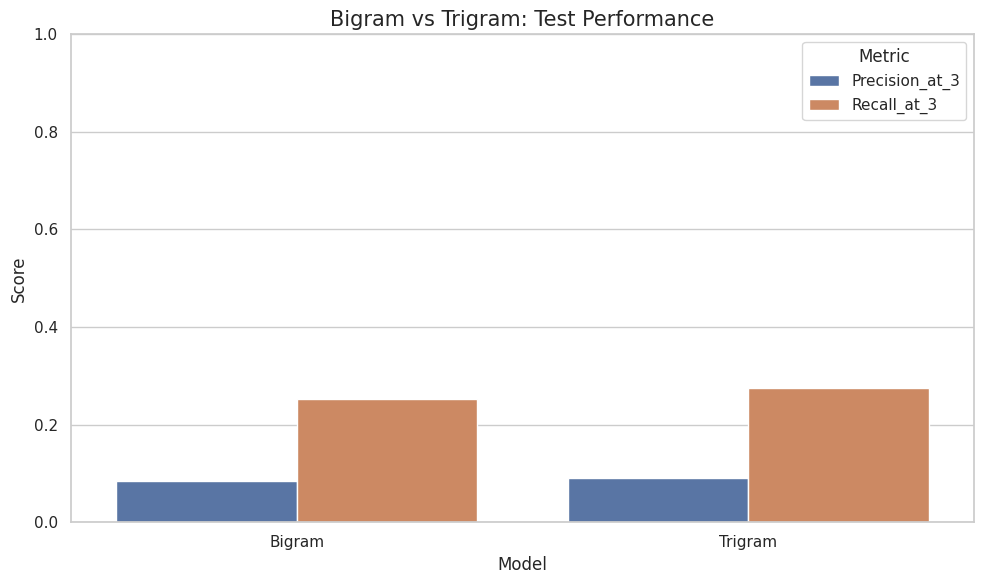

In [18]:
plot_df = test_results.melt(
    id_vars="Model",
    value_vars=[
        "Precision_at_3",
        "Recall_at_3"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title(
    "Bigram vs Trigram: Test Performance",
    fontsize=15
)

plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(
    "autocomplete_comparison.png",
    dpi=170
)
plt.show()

**PART 5 — Making Autocorrect model**  

***STEP 19 — Create edit-distance autocorrect***

In [19]:
ALPHABET = "abcdefghijklmnopqrstuvwxyz"

def edits1(word):

    splits = [
        (word[:i], word[i:])
        for i in range(len(word) + 1)
    ]

    deletes = {
        L + R[1:]
        for L, R in splits
        if R
    }

    transposes = {
        L + R[1] + R[0] + R[2:]
        for L, R in splits
        if len(R) > 1
    }

    replaces = {
        L + c + R[1:]
        for L, R in splits
        if R
        for c in ALPHABET
    }

    inserts = {
        L + c + R
        for L, R in splits
        for c in ALPHABET
    }

    return (
        deletes
        | transposes
        | replaces
        | inserts
    )


def levenshtein(a, b):

    previous = list(range(len(b) + 1))

    for i, char_a in enumerate(a, 1):

        current = [i]

        for j, char_b in enumerate(b, 1):

            current.append(
                min(
                    current[-1] + 1,
                    previous[j] + 1,
                    previous[j - 1] + (char_a != char_b)
                )
            )

        previous = current

    return previous[-1]


spell_vocab = {
    word: count
    for word, count in unigrams.items()
    if count >= 2
    and word.isalpha()
    and len(word) >= 2
}


def autocorrect(word):

    tokens = tokenize(word)

    if not tokens:
        return ""

    word = tokens[0]

    if word in spell_vocab:
        return word

    candidates = (
        edits1(word) & spell_vocab.keys()
    )

    if not candidates:
        return word

    return min(
        candidates,
        key=lambda candidate: (
            levenshtein(word, candidate),
            -spell_vocab[candidate],
            candidate
        )
    )


test_typos = [
    "lern",
    "langauge",
    "computr",
    "scince"
]

for typo in test_typos:
    print(typo, "→", autocorrect(typo))

lern → learn
langauge → language
computr → computer
scince → since


***STEP 20 — Generate 60 misspelled test words***

In [20]:
test_word_counts = Counter(
    word
    for sentence in test_sentences
    for word in sentence
)

eligible = [
    word
    for word, count in test_word_counts.most_common()
    if len(word) >= 6
    and word.isalpha()
    and word in spell_vocab
    and spell_vocab[word] >= 10
]

typo_pairs = []

for word in eligible:

    position = len(word) // 2

    typo = (
        word[:position]
        + word[position + 1:]
    )

    if (
        typo
        and typo != word
        and typo not in spell_vocab
        and all(
            existing_typo != typo
            for existing_typo, _ in typo_pairs
        )
    ):

        typo_pairs.append((typo, word))

    if len(typo_pairs) >= 60:
        break

assert len(typo_pairs) >= 20, (
    "Not enough test cases were generated."
)

print("Generated typos:", len(typo_pairs))

display(
    pd.DataFrame(
        typo_pairs,
        columns=["Misspelling", "Expected Word"]
    ).head(25)
)

Generated typos: 60


,Misspelling,Expected Word
0,durng,during
1,amercan,american
2,tropcal,tropical
3,diviion,division
4,manla,manila
5,thrugh,through
6,briish,british
7,sevral,several
8,befre,before
9,beteen,between


**Thsese are deliberately generated spelling mistakes**

***STEP 21 — Test autocorrect accuracy***

In [21]:
autocorrect_examples = pd.DataFrame([
    {
        "Input": typo,
        "Expected": correct_word,
        "Baseline_Output": typo,
        "Autocorrect_Output": autocorrect(typo)
    }
    for typo, correct_word in typo_pairs
])

autocorrect_examples["Baseline_Correct"] = (
    autocorrect_examples["Baseline_Output"]
    == autocorrect_examples["Expected"]
)

autocorrect_examples["Autocorrect_Correct"] = (
    autocorrect_examples["Autocorrect_Output"]
    == autocorrect_examples["Expected"]
)

display(autocorrect_examples.head(25))

typo_accuracy = (
    autocorrect_examples["Autocorrect_Correct"].mean()
)

print(
    "Misspelling correction accuracy:",
    round(typo_accuracy, 4)
)

,Input,Expected,Baseline_Output,Autocorrect_Output,Baseline_Correct,Autocorrect_Correct
0,durng,during,durng,during,False,True
1,amercan,american,amercan,american,False,True
2,tropcal,tropical,tropcal,tropical,False,True
3,diviion,division,diviion,division,False,True
4,manla,manila,manla,manga,False,False
5,thrugh,through,thrugh,through,False,True
6,briish,british,briish,british,False,True
7,sevral,several,sevral,several,False,True
8,befre,before,befre,before,False,True
9,beteen,between,beteen,between,False,True


Misspelling correction accuracy: 0.9167


***STEP 22 — Autocorrect precision, recall and accuracy***

In [22]:
used_words = {
    correct_word
    for _, correct_word in typo_pairs
}

clean_words = [
    word
    for word in eligible
    if word not in used_words
][:len(typo_pairs)]

spelling_eval = pd.DataFrame(
    [
        {
            "Input": typo,
            "Expected": correct_word,
            "Needs_Correction": True
        }
        for typo, correct_word in typo_pairs
    ]
    +
    [
        {
            "Input": word,
            "Expected": word,
            "Needs_Correction": False
        }
        for word in clean_words
    ]
)

spelling_eval["Prediction"] = (
    spelling_eval["Input"].apply(autocorrect)
)

spelling_eval["Baseline"] = (
    spelling_eval["Input"]
)

spell_metrics = []

for model, column in [
    ("Identity baseline", "Baseline"),
    ("Edit-distance autocorrect", "Prediction")
]:

    spell_metrics.append({
        "Model": model,
        "Samples": len(spelling_eval),

        "Accuracy": accuracy_score(
            spelling_eval["Expected"],
            spelling_eval[column]
        ),

        "Weighted_Precision": precision_score(
            spelling_eval["Expected"],
            spelling_eval[column],
            average="weighted",
            zero_division=0
        ),

        "Weighted_Recall": recall_score(
            spelling_eval["Expected"],
            spelling_eval[column],
            average="weighted",
            zero_division=0
        )
    })

spell_results = pd.DataFrame(spell_metrics)

display(spell_results)

,Model,Samples,Accuracy,Weighted_Precision,Weighted_Recall
0,Identity baseline,120,0.500000,0.500000,0.500000
1,Edit-distance autocorrect,120,0.958333,0.958333,0.958333


***STEP 23 — Correction detection precision and recall***

In [23]:
actual = (
    spelling_eval["Needs_Correction"].astype(int)
)

predicted = (
    spelling_eval["Prediction"]
    != spelling_eval["Input"]
).astype(int)

detection_precision = precision_score(
    actual,
    predicted,
    zero_division=0
)

detection_recall = recall_score(
    actual,
    predicted,
    zero_division=0
)

print(
    "Correction Detection Precision:",
    round(detection_precision, 4)
)

print(
    "Correction Detection Recall:",
    round(detection_recall, 4)
)

Correction Detection Precision: 1.0
Correction Detection Recall: 1.0


In [30]:
# Evaluate whether an attempted correction was actually correct

typo_rows = spelling_eval[
    spelling_eval["Needs_Correction"]
].copy()

typo_rows["Correction_Success"] = (
    typo_rows["Prediction"] == typo_rows["Expected"]
)

successful = int(typo_rows["Correction_Success"].sum())
failed = len(typo_rows) - successful

print("Total misspellings:", len(typo_rows))
print("Correctly corrected:", successful)
print("Incorrectly corrected:", failed)

print(
    "Exact correction accuracy:",
    f"{successful / len(typo_rows):.2%}"
)

display(
    typo_rows.loc[
        ~typo_rows["Correction_Success"],
        ["Input", "Expected", "Prediction"]
    ]
)

Total misspellings: 60
Correctly corrected: 55
Incorrectly corrected: 5
Exact correction accuracy: 91.67%


,Input,Expected,Prediction
4,manla,manila,manga
39,leser,lester,lesser
52,beaty,beauty,beat
56,buter,butler,outer
58,sinle,single,since


***STEP 24 — Autocorrect confusion matrix***

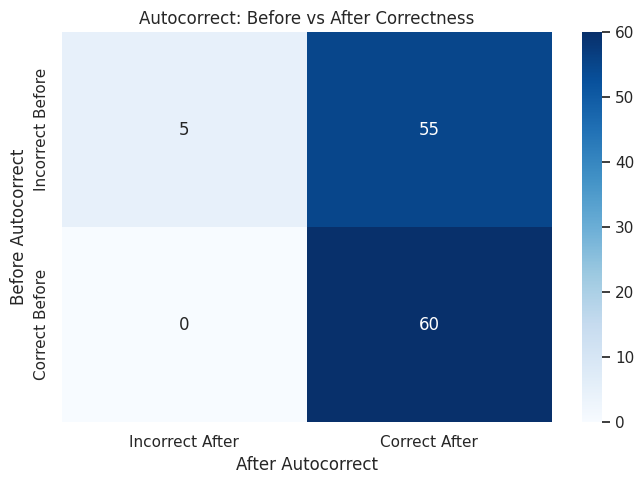

In [24]:
before_correct = (
    spelling_eval["Baseline"]
    == spelling_eval["Expected"]
).astype(int)

after_correct = (
    spelling_eval["Prediction"]
    == spelling_eval["Expected"]
).astype(int)

cm = confusion_matrix(
    before_correct,
    after_correct,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Incorrect After",
        "Correct After"
    ],
    yticklabels=[
        "Incorrect Before",
        "Correct Before"
    ]
)

plt.title(
    "Autocorrect: Before vs After Correctness"
)

plt.xlabel("After Autocorrect")
plt.ylabel("Before Autocorrect")

plt.tight_layout()
plt.savefig(
    "autocorrect_confusion_matrix.png",
    dpi=170
)
plt.show()

##***Observation***

This is a 'before-vs-after' correctness transition matrix. It shows how many words that were previously incorrect have become correct, and whether any words that were already correct have become incorrect.

***STEP 25 — Autocorrect algorithm comparison chart***

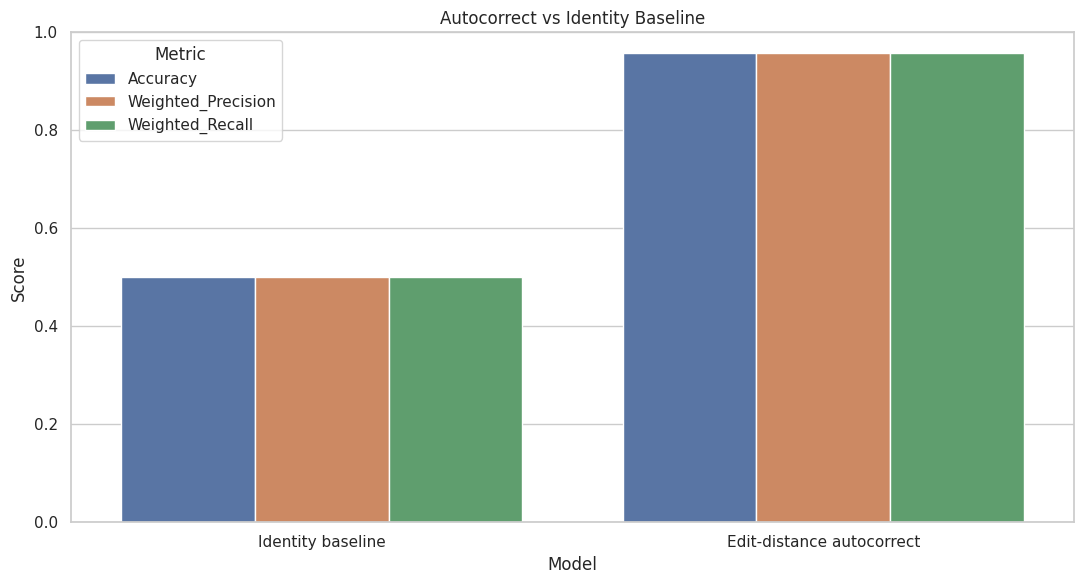

In [25]:
comparison_df = spell_results.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Weighted_Precision",
        "Weighted_Recall"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title(
    "Autocorrect vs Identity Baseline"
)

plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(
    "autocorrect_comparison.png",
    dpi=170
)
plt.show()

***STEP 26 — Successful and failed corrections***

In [26]:
print("Successful corrections:")

display(
    autocorrect_examples[
        autocorrect_examples["Autocorrect_Correct"]
    ].head(12)
)

print("\nFailed corrections:")

display(
    autocorrect_examples[
        ~autocorrect_examples["Autocorrect_Correct"]
    ].head(12)
)

Successful corrections:


,Input,Expected,Baseline_Output,Autocorrect_Output,Baseline_Correct,Autocorrect_Correct
0,durng,during,durng,during,False,True
1,amercan,american,amercan,american,False,True
2,tropcal,tropical,tropcal,tropical,False,True
3,diviion,division,diviion,division,False,True
5,thrugh,through,thrugh,through,False,True
6,briish,british,briish,british,False,True
7,sevral,several,sevral,several,False,True
8,befre,before,befre,before,False,True
9,beteen,between,beteen,between,False,True
10,seaon,season,seaon,season,False,True



Failed corrections:


,Input,Expected,Baseline_Output,Autocorrect_Output,Baseline_Correct,Autocorrect_Correct
4,manla,manila,manla,manga,False,False
39,leser,lester,leser,lesser,False,False
52,beaty,beauty,beaty,beat,False,False
56,buter,butler,buter,outer,False,False
58,sinle,single,sinle,since,False,False


***PART 6 — Model ও results export***

***STEP 27 — Export trained model***

In [31]:
model_artifact = {
    "bigram": {
        key: [
            word
            for word, count in counts.most_common()
        ]
        for key, counts in bigrams.items()
    },

    "trigram": {
        key: [
            word
            for word, count in counts.most_common()
        ]
        for key, counts in trigrams.items()
    },

    "unigrams": dict(unigrams),

    "fallback": fallback,

    "selected_model": best_model
}

with gzip.open(
    "model_artifacts.pkl.gz",
    "wb",
    compresslevel=6
) as file:

    pickle.dump(
        model_artifact,
        file,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print(
    "Full model saved successfully!"
)

print(
    "Model size:",
    round(
        Path("model_artifacts.pkl.gz").stat().st_size
        / 1024**2,
        2
    ),
    "MB"
)

Full model saved successfully!
Model size: 10.26 MB


***STEP 28 — Export metrics, charts and tables***

In [32]:
autocomplete_examples.to_csv(
    "autocomplete_examples.csv",
    index=False
)

autocorrect_examples.to_csv(
    "autocorrect_examples.csv",
    index=False
)

spelling_eval.to_csv(
    "spelling_evaluation.csv",
    index=False
)

top20.to_csv(
    "top20_words.csv",
    index=False
)

val_results.to_csv(
    "autocomplete_validation_metrics.csv",
    index=False
)

test_results.to_csv(
    "autocomplete_test_metrics.csv",
    index=False
)

spell_results.to_csv(
    "autocorrect_metrics.csv",
    index=False
)

summary.to_csv(
    "dataset_summary.csv",
    index=False
)

metrics = {
    "selected_model": best_model,

    "test_autocomplete": (
        test_results.to_dict(orient="records")
    ),

    "autocorrect": (
        spell_results.to_dict(orient="records")
    ),

    "typo_only_accuracy": float(
        autocorrect_examples[
            "Autocorrect_Correct"
        ].mean()
    ),

    "correction_detection_precision": float(
        detection_precision
    ),

    "correction_detection_recall": float(
        detection_recall
    )
}

with open(
    "summary_metrics.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(metrics, file, indent=2)

print("All analysis files exported!")

All analysis files exported!


***STEP 29 — Download all output files***

In [33]:
import zipfile

outputs = [
    "model_artifacts.pkl.gz",
    "summary_metrics.json",
    "top20_words.csv",
    "dataset_summary.csv",

    "autocomplete_examples.csv",
    "autocomplete_validation_metrics.csv",
    "autocomplete_test_metrics.csv",

    "autocorrect_examples.csv",
    "autocorrect_metrics.csv",
    "spelling_evaluation.csv",

    "top20_words.png",
    "text_distributions.png",
    "autocomplete_comparison.png",
    "autocorrect_confusion_matrix.png",
    "autocorrect_comparison.png"
]

with zipfile.ZipFile(
    "task5_outputs.zip",
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in outputs:
        zip_file.write(filename)

print("ZIP created successfully!")

from google.colab import files

files.download("task5_outputs.zip")

ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***STEP 30 — Write the project conclusion***

## Project Conclusion

### Dataset
WikiText-2 English Wikipedia Text Corpus.

### Autocomplete Results
- Best validation-selected model: [Bigram / Trigram]
- Bigram Test Recall@3: [Actual value]
- Trigram Test Recall@3: [Actual value]
- Main observation: [Write based on results]

### Autocorrect Results
- Synthetic misspelling correction accuracy: [Actual value]
- Correction detection precision: [Actual value]
- Correction detection recall: [Actual value]

### Key Insights
1. [Insight from word frequency analysis]
2. [Insight from Bigram vs Trigram comparison]
3. [Insight from autocorrect performance]

### Limitations
- N-gram models capture limited context.
- Edit-distance correction cannot handle every typo.
- Wikipedia language differs from conversational typing.
- Synthetic typo results may not reflect real users.
- Real-word errors require contextual models.

### Future Improvements
- Context-aware spelling correction.
- Larger, more diverse training corpora.
- Transformer-based language models.
- Real-user typing evaluation.